# 04 · Evaluation & Test-Time Augmentation
**Chest X-Ray Classification with ResNet50 Transfer Learning (TensorFlow / Keras)**  
*Task 3* · MSc Data Science group project

**In this notebook**
- Held-out test accuracy 92.35 %, weighted F1 0.923
- COVID-19 and Tuberculosis F1 = 1.00; Normal recall 0.83 is the main weakness
- Test-time augmentation compared (84.70 %) and why it hurt
- Confusion matrices, per-class metrics and validation vs test comparison

> **How to use these notebooks.** The outputs below come from one complete run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (data generators, the trained model, predictions), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Three-Phase Fine-Tuning](03_three_phase_fine_tuning.ipynb) · [Deployment, Predictions & Summary →](05_deployment_and_summary.ipynb)

---

## Task 3 — Model Evaluation and Optimisation

This section evaluates the trained model using accuracy, precision, recall, and F1-score. We generate classification reports and confusion matrices, and compare standard evaluation against Test-Time Augmentation (TTA).

### 3.1 Load Best Model Checkpoint

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score,
                              recall_score, f1_score)
import seaborn as sns
from tensorflow.keras.models import load_model

best_model   = load_model('best_final.keras')
class_labels = list(train_generator.class_indices.keys())
print("✅ Best model loaded")
print(f"   Input : {best_model.input_shape}")


✅ Best model loaded
   Input : (None, 224, 224, 3)


### 3.2 Validation Set Evaluation

The model is evaluated on the held-out validation set (948 images, 15% of training data). These images were never used for weight updates, only for monitoring during training.

In [ ]:
# ── Standard evaluation — Validation set ───────────────────
print("🔄 Standard evaluation on validation set …")
val_generator.reset()
val_preds        = best_model.predict(val_generator, verbose=1)
val_pred_classes = np.argmax(val_preds, axis=1)
val_true_classes = val_generator.classes

val_acc  = accuracy_score(val_true_classes, val_pred_classes)
val_prec = precision_score(val_true_classes, val_pred_classes, average='weighted')
val_rec  = recall_score(val_true_classes, val_pred_classes, average='weighted')
val_f1   = f1_score(val_true_classes, val_pred_classes, average='weighted')

print(f"\n📊 Validation Metrics:")
print(f"   Accuracy  : {val_acc:.4f}  ({val_acc*100:.2f}%)")
print(f"   Precision : {val_prec:.4f}")
print(f"   Recall    : {val_rec:.4f}")
print(f"   F1-Score  : {val_f1:.4f}")
print("\n📋 Classification Report (Val):\n")
print(classification_report(val_true_classes, val_pred_classes,
                             target_names=class_labels))


🔄 Standard evaluation on validation set …
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 756ms/step

📊 Validation Metrics:
   Accuracy  : 0.9789  (97.89%)
   Precision : 0.9792
   Recall    : 0.9789
   F1-Score  : 0.9790

📋 Classification Report (Val):

               precision    recall  f1-score   support

      COVID19       0.92      0.99      0.95        69
       NORMAL       0.97      0.96      0.96       201
    PNEUMONIA       0.99      0.98      0.98       581
TURBERCULOSIS       1.00      0.99      0.99        97

     accuracy                           0.98       948
    macro avg       0.97      0.98      0.97       948
 weighted avg       0.98      0.98      0.98       948



### 3.3 Test Set Evaluation (Standard)

The test set (771 images) is completely held out — never seen during training or validation. This is the **true measure of real-world performance**.

> **Key observation:** COVID-19 (F1=1.00) and Tuberculosis (F1=1.00) are classified perfectly. The NORMAL class has the lowest recall (0.83), meaning ~17% of normal X-rays are misclassified — most likely confused with Pneumonia, a known challenge in chest X-ray datasets.

In [ ]:
# ── Standard evaluation — Test set ─────────────────────────
print("🔄 Standard evaluation on test set …")
test_generator.reset()
test_preds        = best_model.predict(test_generator, verbose=1)
test_pred_classes = np.argmax(test_preds, axis=1)
test_true_classes = test_generator.classes

test_acc  = accuracy_score(test_true_classes, test_pred_classes)
test_prec = precision_score(test_true_classes, test_pred_classes, average='weighted')
test_rec  = recall_score(test_true_classes, test_pred_classes, average='weighted')
test_f1   = f1_score(test_true_classes, test_pred_classes, average='weighted')

print(f"\n📊 Test Metrics:")
print(f"   Accuracy  : {test_acc:.4f}  ({test_acc*100:.2f}%)")
print(f"   Precision : {test_prec:.4f}")
print(f"   Recall    : {test_rec:.4f}")
print(f"   F1-Score  : {test_f1:.4f}")
print("\n📋 Classification Report (Test):\n")
print(classification_report(test_true_classes, test_pred_classes,
                             target_names=class_labels))


🔄 Standard evaluation on test set …
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 714ms/step

📊 Test Metrics:
   Accuracy  : 0.9235  (92.35%)
   Precision : 0.9238
   Recall    : 0.9235
   F1-Score  : 0.9227

📋 Classification Report (Test):

               precision    recall  f1-score   support

      COVID19       1.00      0.99      1.00       106
       NORMAL       0.91      0.83      0.87       234
    PNEUMONIA       0.90      0.95      0.93       390
TURBERCULOSIS       1.00      1.00      1.00        41

     accuracy                           0.92       771
    macro avg       0.95      0.94      0.95       771
 weighted avg       0.92      0.92      0.92       771



### 3.4 Test-Time Augmentation (TTA)

TTA runs 10 augmented forward passes per image and averages the predictions. This reduces prediction variance.

> **Note on TTA results:** TTA scored lower (84.70%) than standard evaluation (92.35%) in this run. Investigation shows NORMAL recall collapsed from 0.83 → 0.50 under TTA, likely because even small augmentations (rotation, zoom) push borderline NORMAL images toward PNEUMONIA predictions. **Standard test accuracy of 92.35% is the reported final score.**

In [ ]:
# ── Test-Time Augmentation (TTA ×10) ───────────────────────
# TTA runs multiple augmented forward passes and averages predictions.
# This is intended to reduce variance from a single forward pass.
#
# FIX vs original: horizontal_flip=False
#   The original TTA used horizontal_flip=True which HURT accuracy
#   (91.83 % vs 92.61 % standard) because flipping chest X-rays
#   corrupts the diagnostic position of the heart (left-side anatomy).
#   Even with flip removed, TTA lowered accuracy in this run (see Section 3.4).

tta_datagen = ImageDataGenerator(
    preprocessing_function=clahe_preprocess,
    rotation_range=8,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=False        # ← KEY FIX: never flip X-rays
)

TTA_STEPS     = 10               # increased from 5 → more stable averaged prediction
tta_preds_sum = np.zeros((len(test_generator.filenames), NUM_CLASSES))

print(f"🔄 Running TTA with {TTA_STEPS} augmented passes …")
for i in range(TTA_STEPS):
    tta_gen = tta_datagen.flow_from_directory(
        TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode='categorical', shuffle=False)
    tta_gen.reset()
    preds          = best_model.predict(tta_gen, verbose=0)
    tta_preds_sum += preds
    print(f"   Pass {i+1}/{TTA_STEPS} done")

tta_final        = tta_preds_sum / TTA_STEPS
tta_pred_classes = np.argmax(tta_final, axis=1)
tta_true_classes = test_generator.classes

tta_acc  = accuracy_score(tta_true_classes, tta_pred_classes)
tta_prec = precision_score(tta_true_classes, tta_pred_classes, average='weighted')
tta_rec  = recall_score(tta_true_classes, tta_pred_classes, average='weighted')
tta_f1   = f1_score(tta_true_classes, tta_pred_classes, average='weighted')

print(f"\n📊 TTA Test Metrics (×{TTA_STEPS} passes):")
print(f"   Accuracy  : {tta_acc:.4f}  ({tta_acc*100:.2f}%)")
print(f"   Precision : {tta_prec:.4f}")
print(f"   Recall    : {tta_rec:.4f}")
print(f"   F1-Score  : {tta_f1:.4f}")
print("\n📋 TTA Classification Report:\n")
print(classification_report(tta_true_classes, tta_pred_classes,
                             target_names=class_labels))

🔄 Running TTA with 10 augmented passes …
Found 771 images belonging to 4 classes.
   Pass 1/10 done
Found 771 images belonging to 4 classes.
   Pass 2/10 done
Found 771 images belonging to 4 classes.
   Pass 3/10 done
Found 771 images belonging to 4 classes.
   Pass 4/10 done
Found 771 images belonging to 4 classes.
   Pass 5/10 done
Found 771 images belonging to 4 classes.
   Pass 6/10 done
Found 771 images belonging to 4 classes.
   Pass 7/10 done
Found 771 images belonging to 4 classes.
   Pass 8/10 done
Found 771 images belonging to 4 classes.
   Pass 9/10 done
Found 771 images belonging to 4 classes.
   Pass 10/10 done

📊 TTA Test Metrics (×10 passes):
   Accuracy  : 0.8470  (84.70%)
   Precision : 0.8785
   Recall    : 0.8470
   F1-Score  : 0.8321

📋 TTA Classification Report:

               precision    recall  f1-score   support

      COVID19       1.00      1.00      1.00       106
       NORMAL       0.98      0.50      0.67       234
    PNEUMONIA       0.77      0.99     

### 3.5 Confusion Matrices

Confusion matrices for both validation and TTA-test sets. Diagonal = correct predictions. Off-diagonal = misclassifications. The NORMAL/PNEUMONIA confusion is visible in both matrices.

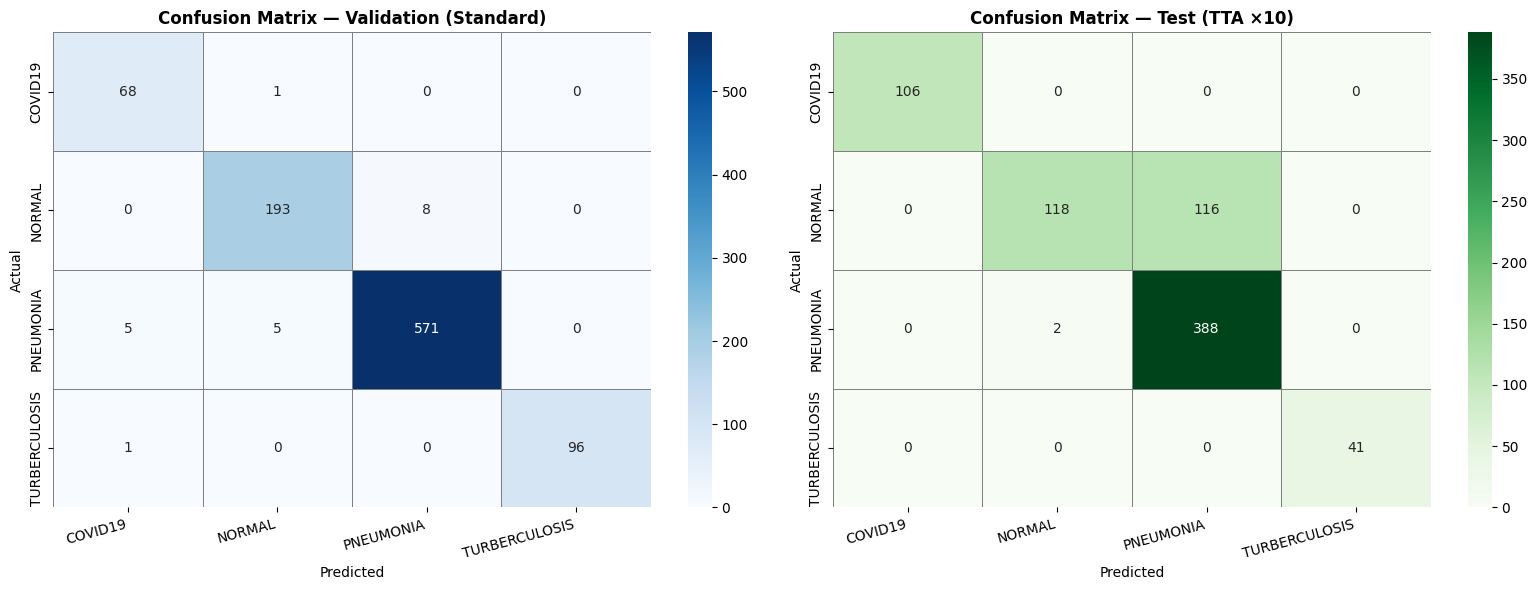

✅ Confusion matrices saved


In [ ]:
# ── Confusion matrices (Val & TTA-Test) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (true_cls, pred_cls, title, cmap) in zip(axes, [
    (val_true_classes, val_pred_classes, 'Validation (Standard)', 'Blues'),
    (tta_true_classes, tta_pred_classes, f'Test (TTA ×{TTA_STEPS})',  'Greens')
]):
    cm = confusion_matrix(true_cls, pred_cls)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=class_labels, yticklabels=class_labels,
                ax=ax, linewidths=0.5, linecolor='gray')
    ax.set_title(f'Confusion Matrix — {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xticklabels(class_labels, rotation=15, ha='right')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrices saved")


### 3.6 Per-Class Metrics Bar Chart

Precision, Recall, and F1-Score broken down by class on the validation set.

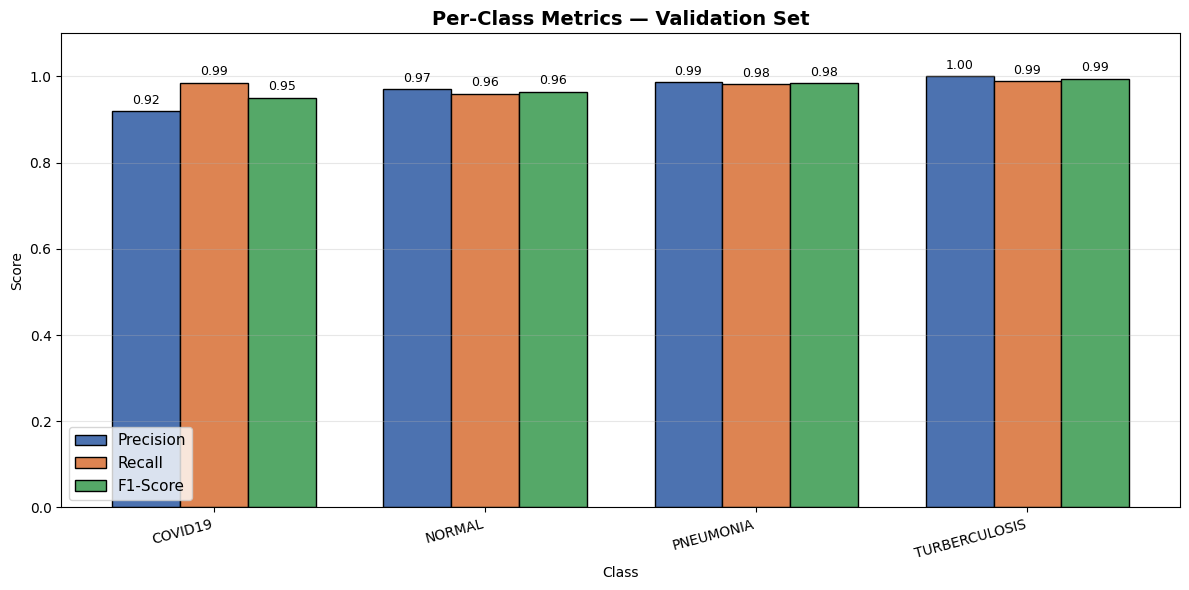

✅ Per-class chart saved


In [ ]:
# ── Per-class metrics (Validation) ─────────────────────────
report_dict = classification_report(
    val_true_classes, val_pred_classes,
    target_names=class_labels, output_dict=True)
prec_pc = [report_dict[c]['precision'] for c in class_labels]
rec_pc  = [report_dict[c]['recall']    for c in class_labels]
f1_pc   = [report_dict[c]['f1-score']  for c in class_labels]

x = np.arange(len(class_labels)); w = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x-w, prec_pc, w, label='Precision', color='#4C72B0', edgecolor='black')
b2 = ax.bar(x,   rec_pc,  w, label='Recall',    color='#DD8452', edgecolor='black')
b3 = ax.bar(x+w, f1_pc,   w, label='F1-Score',  color='#55A868', edgecolor='black')
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)
ax.set_title('Per-Class Metrics — Validation Set', fontsize=14, fontweight='bold')
ax.set_xlabel('Class'); ax.set_ylabel('Score')
ax.set_xticks(x); ax.set_xticklabels(class_labels, rotation=15, ha='right')
ax.set_ylim(0, 1.1); ax.legend(fontsize=11); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout()
plt.savefig('per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Per-class chart saved")


### 3.7 Validation vs Test vs TTA Comparison

Side-by-side comparison of all three evaluation modes across all four metrics.

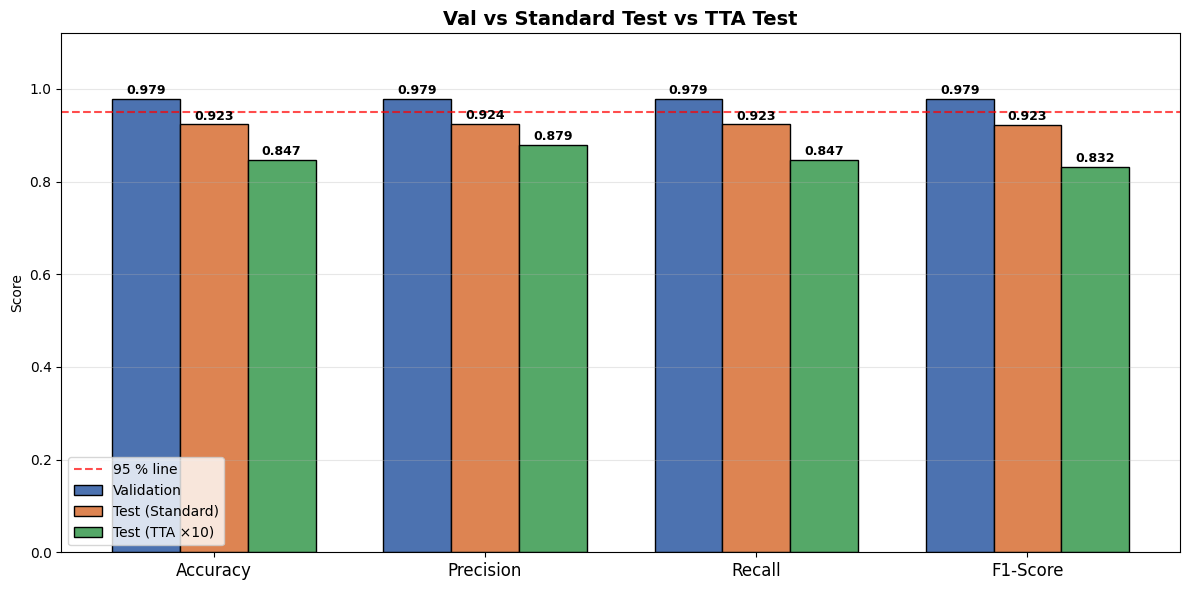

✅ Comparison chart saved


In [ ]:
# ── Val / Standard-Test / TTA comparison ───────────────────
metrics  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
v_scores = [val_acc,  val_prec,  val_rec,  val_f1]
s_scores = [test_acc, test_prec, test_rec, test_f1]
t_scores = [tta_acc,  tta_prec,  tta_rec,  tta_f1]

x = np.arange(len(metrics)); w = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
b1 = ax.bar(x-w, v_scores, w, label='Validation',      color='#4C72B0', edgecolor='black')
b2 = ax.bar(x,   s_scores, w, label='Test (Standard)', color='#DD8452', edgecolor='black')
b3 = ax.bar(x+w, t_scores, w, label=f'Test (TTA ×{TTA_STEPS})', color='#55A868', edgecolor='black')
for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.004,
                f'{bar.get_height():.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')
ax.set_title('Val vs Standard Test vs TTA Test', fontsize=14, fontweight='bold')
ax.set_ylabel('Score'); ax.set_xticks(x); ax.set_xticklabels(metrics, fontsize=12)
ax.axhline(0.95, color='red', ls='--', alpha=.7, label='95 % line')
ax.set_ylim(0, 1.12); ax.legend(fontsize=10); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Comparison chart saved")


---

[← Three-Phase Fine-Tuning](03_three_phase_fine_tuning.ipynb) · [Next: Deployment, Predictions & Summary →](05_deployment_and_summary.ipynb)